# Combined Multi-Dataset Preparation: Kids vs Adults


**Datasets combined (3 sources), each doing a different job:**

| Dataset | Role |
|---|---|
| **FG-NET** | Only good public source of *same-identity* photos spanning childhood years -> genuine pairs for **Kids** |
| **CACD2000** | Same-identity celebrity photos across years, mostly adults -> genuine pairs for **Adults** |
| **UTKFace** | Large single-image, age-labeled dataset (no repeat identities) -> used only to **enlarge the impostor/distractor pool** for both categories in Notebook 4 |




## 1. Download all 3 datasets



In [1]:
import kagglehub

In [2]:
cacd_path = kagglehub.dataset_download("linhhunhnht/cacd2000-face-5-1100-s")

# bostankhan6/cacd2000
print("CACD2000 at:", cacd_path)


CACD2000 at: C:\Users\bhavi\.cache\kagglehub\datasets\linhhunhnht\cacd2000-face-5-1100-s\versions\1


**UTKFace** (aligned & cropped version, Kaggle mirror):


In [3]:
utkface_path = kagglehub.dataset_download("jangedoo/utkface-new")
print("UTKFace at:", utkface_path)


UTKFace at: C:\Users\bhavi\.cache\kagglehub\datasets\jangedoo\utkface-new\versions\1


In [4]:
fgnet_path = kagglehub.dataset_download("aiolapo/fgnet-dataset")
print("FaceNet at:", fgnet_path)


FaceNet at: C:\Users\bhavi\.cache\kagglehub\datasets\aiolapo\fgnet-dataset\versions\1


In [5]:
import os

# FGNET_DIR = "./fgnet_raw/FGNET/images"        # adjust after checking actual unzip layout
FGNET_DIR =fgnet_path
CACD_DIR = cacd_path                          # e.g. ".../CACD2000"
UTKFACE_DIR = os.path.join(utkface_path, "UTKFace")  # adjust if nested differently

for name, d in [("FG-NET", FGNET_DIR), ("CACD2000", CACD_DIR), ("UTKFace", UTKFACE_DIR)]:
    exists = os.path.isdir(d)
    n = len(os.listdir(d)) if exists else 0
    print(f"{name}: {d}  exists={exists}  n_files={n}")


FG-NET: C:\Users\bhavi\.cache\kagglehub\datasets\aiolapo\fgnet-dataset\versions\1  exists=True  n_files=1
CACD2000: C:\Users\bhavi\.cache\kagglehub\datasets\linhhunhnht\cacd2000-face-5-1100-s\versions\1  exists=True  n_files=1
UTKFace: C:\Users\bhavi\.cache\kagglehub\datasets\jangedoo\utkface-new\versions\1\UTKFace  exists=True  n_files=23708


## 2. Parse FG-NET (Kids source)



In [6]:


import os
import re
import pandas as pd

def parse_fgnet_filename(fname):
    # Matches FG-NET filenames such as:
    # 001A01.JPG
    # 001A12.jpg
    # 001A01.png
    m = re.search(r"(\d{3})A(\d{2})\.(jpg|jpeg|png)$", fname, re.IGNORECASE)

    if not m:
        return None

    subject_id = m.group(1)
    age = int(m.group(2))

    return subject_id, age


fgnet_records = []

# os.walk() searches through FGNET_DIR and its subfolders
for root, dirs, files in os.walk(FGNET_DIR):
    for f in files:

        parsed = parse_fgnet_filename(f)

        if parsed is None:
            continue

        sid, age = parsed

        fgnet_records.append({
            "filename": f,
            "identity": f"fgnet_{sid}",
            "age": age,
            "path": os.path.join(root, f)
        })


# Keep the same variable name for later tasks
fgnet_df_raw = pd.DataFrame(
    fgnet_records,
    columns=["filename", "identity", "age", "path"]
)

print(
    "FG-NET parsed images:",
    len(fgnet_df_raw),
    " | unique identities:",
    fgnet_df_raw["identity"].nunique()
)

fgnet_df_raw.head()




FG-NET parsed images: 974  | unique identities: 82


,filename,identity,age,path
0,001A02.JPG,fgnet_001,2,C:\Users\bhavi\.cache\kagglehub\datasets\aiola...
1,001A05.JPG,fgnet_001,5,C:\Users\bhavi\.cache\kagglehub\datasets\aiola...
2,001A08.JPG,fgnet_001,8,C:\Users\bhavi\.cache\kagglehub\datasets\aiola...
3,001A10.JPG,fgnet_001,10,C:\Users\bhavi\.cache\kagglehub\datasets\aiola...
4,001A14.JPG,fgnet_001,14,C:\Users\bhavi\.cache\kagglehub\datasets\aiola...


## 3. Parse CACD2000 (Adults source)

In [7]:
import os
import re
import pandas as pd

def parse_cacd_filename(fname):
    stem = os.path.splitext(fname)[0]
    parts = stem.split("_")

    # First part should be the age
    try:
        age = int(parts[0])
    except (ValueError, IndexError):
        return None

    # Extract identity/name
    name = "_".join(parts[1:-1]) if len(parts) > 2 else "_".join(parts[1:])

    # Make sure an identity exists
    if not name:
        return None

    return age, name


cacd_records = []

# os.walk() searches CACD_DIR and all its subdirectories
for root, dirs, files in os.walk(CACD_DIR):
    for f in files:

        # Only process image files
        if not f.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        parsed = parse_cacd_filename(f)

        if parsed is None:
            continue

        age, name = parsed

        cacd_records.append({
            "filename": f,
            "identity": f"cacd_{name}",
            "age": age,
            "path": os.path.join(root, f)
        })


# Keep the same variable name for later tasks
cacd_df_raw = pd.DataFrame(
    cacd_records,
    columns=["filename", "identity", "age", "path"]
)

print(
    "CACD2000 parsed images:",
    len(cacd_df_raw),
    " | unique identities:",
    cacd_df_raw["identity"].nunique()
)

cacd_df_raw.head()


CACD2000 parsed images: 5500  | unique identities: 4367


,filename,identity,age,path
0,29_Stacy_Keibler_0008_face_0.jpg,cacd_Stacy_Keibler_0008_face,29,C:\Users\bhavi\.cache\kagglehub\datasets\linhh...
1,29_Stana_Katic_0001_face_0.jpg,cacd_Stana_Katic_0001_face,29,C:\Users\bhavi\.cache\kagglehub\datasets\linhh...
2,29_Stephanie_Leonidas_0002_face_0.jpg,cacd_Stephanie_Leonidas_0002_face,29,C:\Users\bhavi\.cache\kagglehub\datasets\linhh...
3,29_Stephen_Amell_0015_face_0.jpg,cacd_Stephen_Amell_0015_face,29,C:\Users\bhavi\.cache\kagglehub\datasets\linhh...
4,29_Steve_Howey_0010_face_0.jpg,cacd_Steve_Howey_0010_face,29,C:\Users\bhavi\.cache\kagglehub\datasets\linhh...


## 4. Parse UTKFace (impostor/distractor pool only — no genuine pairs possible)




In [8]:
def parse_utkface_filename(fname):
    stem = os.path.splitext(fname)[0]
    parts = stem.split("_")
    try:
        age = int(parts[0])
    except (ValueError, IndexError):
        return None
    return age

utk_records = []
for f in os.listdir(UTKFACE_DIR):
    if not f.lower().endswith((".jpg", ".jpeg", ".png")):
        continue
    age = parse_utkface_filename(f)
    if age is None:
        continue
    utk_records.append({"filename": f, "age": age, "path": os.path.join(UTKFACE_DIR, f)})

utk_df_raw = pd.DataFrame(utk_records)
print("UTKFace parsed images:", len(utk_df_raw))
utk_df_raw.head()


UTKFace parsed images: 23708


,filename,age,path
0,100_0_0_20170112213500903.jpg.chip.jpg,100,C:\Users\bhavi\.cache\kagglehub\datasets\jange...
1,100_0_0_20170112215240346.jpg.chip.jpg,100,C:\Users\bhavi\.cache\kagglehub\datasets\jange...
2,100_1_0_20170110183726390.jpg.chip.jpg,100,C:\Users\bhavi\.cache\kagglehub\datasets\jange...
3,100_1_0_20170112213001988.jpg.chip.jpg,100,C:\Users\bhavi\.cache\kagglehub\datasets\jange...
4,100_1_0_20170112213303693.jpg.chip.jpg,100,C:\Users\bhavi\.cache\kagglehub\datasets\jange...


## 5. MTCNN face-detection filter (applied to all 3 sources)

In [9]:
import os
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from facenet_pytorch import MTCNN


# GPU SETUP


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    torch.backends.cudnn.benchmark = True



# MTCNN


mtcnn = MTCNN(
    image_size=160,
    margin=20,
    keep_all=True,
    post_process=True,
    device=device
)

print("MTCNN device:", device)



# IMAGE RESIZE + PADDING


TARGET_SIZE = (320, 320)


def resize_and_pad(img, target_size=TARGET_SIZE):

    target_w, target_h = target_size

    # Original dimensions
    w, h = img.size

    # Preserve aspect ratio
    scale = min(
        target_w / w,
        target_h / h
    )

    new_w = int(w * scale)
    new_h = int(h * scale)

    # Resize
    img = img.resize(
        (new_w, new_h),
        Image.Resampling.BILINEAR
    )

    # Create black canvas
    canvas = Image.new(
        "RGB",
        target_size,
        (0, 0, 0)
    )

    # Center image
    left = (target_w - new_w) // 2
    top = (target_h - new_h) // 2

    canvas.paste(
        img,
        (left, top)
    )

    return canvas



# DATASET


class FaceDataset(Dataset):

    def __init__(
        self,
        paths,
        target_size=(320, 320)
    ):
        self.paths = paths
        self.target_size = target_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        path = self.paths[idx]

        try:

            img = Image.open(path).convert("RGB")

            # Make every image the same size
            img = resize_and_pad(
                img,
                self.target_size
            )

            return img, idx

        except Exception as e:

            return None, idx



# COLLATE FUNCTION


def collate_fn(batch):

    images = []
    indices = []

    for img, idx in batch:

        if img is not None:

            images.append(img)
            indices.append(idx)

    return images, indices



# FAST FACE FILTER



@torch.inference_mode()
def filter_faces(
    df,
    name,
    batch_size=64,
    min_prob=0.7,
    num_workers=3
):

    df = df.copy()

    paths = df["path"].tolist()

    dataset = FaceDataset(
        paths,
        target_size=(320, 320)
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        collate_fn=collate_fn,
        persistent_workers=(num_workers > 0)
    )

    has_face = np.zeros(
        len(paths),
        dtype=bool
    )

    for images, indices in tqdm(
        loader,
        desc=f"MTCNN filter: {name}",
        total=len(loader)
    ):

        if len(images) == 0:
            continue

        try:

            
            # Detect faces
            

            boxes, probs = mtcnn.detect(images)

            
            # Process each image separately
            

            if probs is None:
                continue

            for local_idx, original_idx in enumerate(indices):

                image_probs = probs[local_idx]

                # No face detected
                if image_probs is None:
                    continue

                # Convert to numpy array safely
                image_probs = np.asarray(
                    image_probs,
                    dtype=object
                )

                # Remove None values
                valid_probs = []

                for p in image_probs.flatten():

                    if p is None:
                        continue

                    try:
                        p = float(p)
                        valid_probs.append(p)
                    except (TypeError, ValueError):
                        continue

                # No valid probabilities
                if len(valid_probs) == 0:
                    continue

                # Keep image if ANY face exceeds threshold
                if max(valid_probs) >= min_prob:
                    has_face[original_idx] = True

        except Exception as e:

            print(
                f"\nBatch error in {name}: {e}"
            )

    
    # Add result
    

    df["has_face"] = has_face

    df = df.loc[
        df["has_face"]
    ].reset_index(drop=True)

    return df


# RUN


fgnet_df = filter_faces(
    fgnet_df_raw,
    "FG-NET",
    batch_size=64,
    min_prob=0.6,
    num_workers=0
)

cacd_df = filter_faces(
    cacd_df_raw,
    "CACD2000",
    batch_size=64,
    min_prob=0.6,
    num_workers=0
)

utk_df = filter_faces(
    utk_df_raw,
    "UTKFace",
    batch_size=64,
    min_prob=0.6,
    num_workers=0
)

print(
    "\nAfter MTCNN filter -> "
    f"FG-NET: {len(fgnet_df)} | "
    f"CACD2000: {len(cacd_df)} | "
    f"UTKFace: {len(utk_df)}"
)


Device: cpu
MTCNN device: cpu


MTCNN filter: FG-NET:   0%|          | 0/16 [00:00<?, ?it/s]

MTCNN filter: CACD2000:   0%|          | 0/86 [00:00<?, ?it/s]

MTCNN filter: UTKFace:   0%|          | 0/371 [00:00<?, ?it/s]


After MTCNN filter -> FG-NET: 970 | CACD2000: 5496 | UTKFace: 23664


## 6. Build genuine pairs with the 5-year-minimum rule, split by life stage


In [10]:
MIN_GAP_YEARS = 5
ADULT_AGE_THRESHOLD = 18

def build_pairs(df, min_gap=MIN_GAP_YEARS):
    out = []
    for name, g in df.groupby("identity"):
        if g["age"].nunique() < 2:
            continue
        oldest = g.loc[g["age"].idxmin()]
        newest = g.loc[g["age"].idxmax()]
        gap = newest["age"] - oldest["age"]
        if gap >= min_gap:
            out.append({
                "identity": name, "age_old": oldest["age"], "age_new": newest["age"],
                "age_gap": gap, "path_old": oldest["path"], "path_new": newest["path"],
                "source": name.split("_")[0],
            })
    return pd.DataFrame(out)

fgnet_pairs = build_pairs(fgnet_df_raw)
cacd_pairs = build_pairs(cacd_df_raw,min_gap=2)

kids_pairs = fgnet_pairs[(fgnet_pairs["age_old"] < ADULT_AGE_THRESHOLD) &(fgnet_pairs["age_new"] < ADULT_AGE_THRESHOLD)].copy()

adults_candidates = pd.concat([
    cacd_pairs[(cacd_pairs["age_old"] >= ADULT_AGE_THRESHOLD) &
               (cacd_pairs["age_new"] >= ADULT_AGE_THRESHOLD)],
    fgnet_pairs[(fgnet_pairs["age_old"] >= ADULT_AGE_THRESHOLD) &
                (fgnet_pairs["age_new"] >= ADULT_AGE_THRESHOLD)],
], ignore_index=True)

print("Kids candidate pairs (FG-NET only):", len(kids_pairs))
print("Adults candidate pairs (FG-NET + CACD2000):", len(adults_candidates))


Kids candidate pairs (FG-NET only): 18
Adults candidate pairs (FG-NET + CACD2000): 385


## 7. Balance sample sizes and export both categories

We cap **both** categories at the same N (the smaller of the two, up to a max of 100) so the
Notebook 5 comparison isn't confounded by sample-size differences.


In [15]:
import shutil

MAX_PER_CATEGORY = 100
N = min(len(kids_pairs), len(adults_candidates), MAX_PER_CATEGORY)
print(f"Using N = {N} subjects per category")

kids_final = kids_pairs.sample(n=len(kids_pairs), random_state=42).reset_index(drop=True)
adults_final = adults_candidates.sample(n=len(adults_candidates), random_state=42).reset_index(drop=True)

def export_category(pairs_df, out_dir, category_name):
    os.makedirs(out_dir, exist_ok=True)
    pairs_df = pairs_df.copy()
    pairs_df["subject_id"] = [f"{i:04d}" for i in range(len(pairs_df))]
    for _, row in tqdm(pairs_df.iterrows(), total=len(pairs_df), desc=f"Exporting {category_name}"):
        sid = row["subject_id"]
        shutil.copy(row["path_old"], os.path.join(out_dir, f"{sid}_0.jpg"))
        shutil.copy(row["path_new"], os.path.join(out_dir, f"{sid}_1.jpg"))
    meta_cols = ["subject_id", "identity", "source", "age_old", "age_new", "age_gap"]
    pairs_df[meta_cols].to_csv(os.path.join(out_dir, "metadata.csv"), index=False)
    return pairs_df

OUTPUT_ROOT = "./dataset_v2"
kids_meta = export_category(kids_final, os.path.join(OUTPUT_ROOT, "kids"), "kids")
adults_meta = export_category(adults_final, os.path.join(OUTPUT_ROOT, "adults"), "adults")

print("Kids category:", len(kids_meta), "subjects")
print("Adults category:", len(adults_meta), "subjects")


Using N = 18 subjects per category


Exporting kids:   0%|          | 0/18 [00:00<?, ?it/s]

Exporting adults:   0%|          | 0/385 [00:00<?, ?it/s]

Kids category: 18 subjects
Adults category: 385 subjects


## 8. Export the UTKFace impostor/distractor pool (split by age too)

These images are **not** used as genuine pairs (UTKFace has no repeat identities) — they only
enlarge the pool of "different-subject" faces available when Notebook 4 samples impostor
pairs, which gives a more realistic (larger, more diverse) impostor distribution.


In [16]:
utk_kids_pool = utk_df[utk_df["age"] < ADULT_AGE_THRESHOLD].reset_index(drop=True)
utk_adults_pool = utk_df[utk_df["age"] >= ADULT_AGE_THRESHOLD].reset_index(drop=True)

DISTRACTOR_N = 200  # how many extra distractor faces per category to export

def export_distractor_pool(pool_df, out_dir, n):
    os.makedirs(out_dir, exist_ok=True)
    sample = pool_df.sample(n=min(n, len(pool_df)), random_state=42).reset_index(drop=True)
    for i, row in tqdm(sample.iterrows(), total=len(sample), desc=f"Exporting distractors -> {out_dir}"):
        shutil.copy(row["path"], os.path.join(out_dir, f"distractor_{i:04d}.jpg"))
    return sample

export_distractor_pool(utk_kids_pool, os.path.join(OUTPUT_ROOT, "kids", "distractors"), DISTRACTOR_N)
export_distractor_pool(utk_adults_pool, os.path.join(OUTPUT_ROOT, "adults", "distractors"), DISTRACTOR_N)
print("Distractor pools exported.")


Exporting distractors -> ./dataset_v2\kids\distractors:   0%|          | 0/200 [00:00<?, ?it/s]

Exporting distractors -> ./dataset_v2\adults\distractors:   0%|          | 0/200 [00:00<?, ?it/s]

Distractor pools exported.


## 9. Sanity-check plots

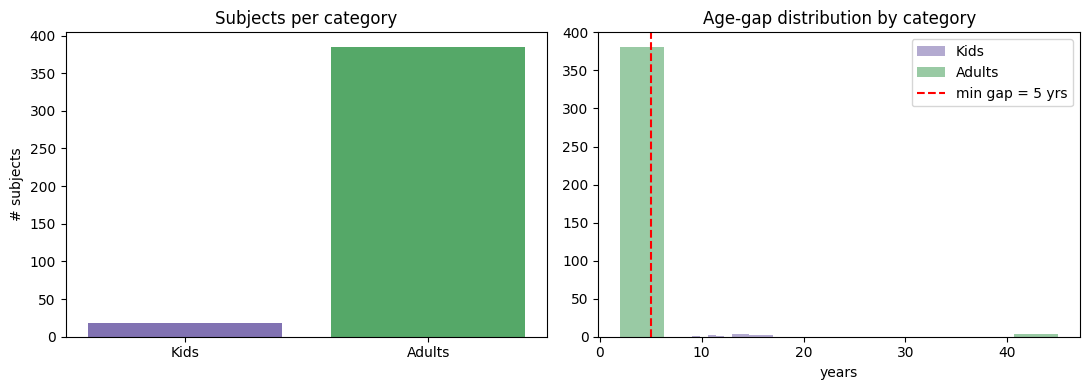

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Kids", "Adults"], [len(kids_meta), len(adults_meta)], color=["#8172B2", "#55A868"])
axes[0].set_title("Subjects per category")
axes[0].set_ylabel("# subjects")

axes[1].hist(kids_meta["age_gap"], bins=10, alpha=0.6, label="Kids", color="#8172B2")
axes[1].hist(adults_meta["age_gap"], bins=10, alpha=0.6, label="Adults", color="#55A868")
axes[1].axvline(5, color="red", linestyle="--", label="min gap = 5 yrs")
axes[1].set_title("Age-gap distribution by category")
axes[1].set_xlabel("years")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "kids_vs_adults_dataset_summary.png"), dpi=150)
plt.show()
